# Clase 9: Matriz de Costos Económicos y Threshold Tuning

### Machine Learning (RIA-805) — Bloque 2 — Factibilidad Técnico-Financiera

**Docente:** Marco Capio  
**Fecha:** Semana 2 del bloque comprimido

**Objetivo:** Traducir errores algorítmicos (FP y FN) a dólares y encontrar el umbral de decisión que minimiza el costo total del modelo.

**Conexión con la práctica:** En P2 aplicarán esto a su modelo de Wall-Following y aprenderán a justificar económicamente su umbral de decisión.

## ¿Dónde estamos?

En la **Clase 8** vimos que el accuracy puede ser engañoso en datos desbalanceados y que precision, recall y F1 describen mejor el rendimiento de la clase minoritaria. Sin embargo, estas métricas no responden una pregunta de negocio: **¿cuánto cuesta equivocarse?**

Hoy asignaremos un costo a cada tipo de error y compararemos decisiones posibles para elegir el umbral que minimiza el costo total.

## ¿Qué es la matriz de costos?

Una **matriz de costos** asigna un valor económico a cada combinación de clase real y predicción. Para este ejercicio asumimos que una predicción positiva correcta (**TP**) y una predicción negativa correcta (**TN**) no generan costo adicional en el modelo simplificado. Los errores sí tienen costo:

| Clase real | Predicción positiva | Predicción negativa |
|---|---:|---:|
| Positiva (`rice`) | TP: $0 | FN: **C_FN** |
| Negativa (`no rice`) | FP: **C_FP** | TN: $0 |

El costo total es **Costo = FP × C_FP + FN × C_FN**. Esta es una simplificación: en un análisis real también pueden incluirse costos de intervención, operación, oportunidad y beneficios de aciertos.

> **Los costos no salen del modelo: salen del negocio.** Deben estimarse con personas expertas, datos operativos y supuestos explícitos.

## Ejemplos de costos por contexto

Los valores siguientes son **ejemplos ilustrativos por evento**, no tarifas universales. La relación entre falsos positivos y falsos negativos cambia según el proceso y sus consecuencias.

| Contexto | C_FP (falso positivo) | C_FN (falso negativo) | Prioridad posible |
|---|---:|---:|---|
| Mantenimiento predictivo | $200: inspección preventiva innecesaria | $5,000: daño y parada no anticipados | Reducir FN si una avería es crítica |
| Detección de fraude | $20: revisión o bloqueo de una compra legítima | $500: fraude no detectado | Balancear fraude evitado con fricción al cliente |
| Diagnóstico médico | $100: prueba adicional | $10,000: daño esperado por diagnóstico tardío | Reducir FN; las decisiones clínicas requieren protocolos expertos |
| Recomendación de cultivo | $50: insumo aplicado innecesariamente | $500: pérdida de cosecha por no recomendar `rice` cuando convenía | Reducir FN, controlando también el costo de falsas alarmas |

La prioridad es una decisión contextual, no una propiedad intrínseca del algoritmo.

In [1]:
%matplotlib inline

import os
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, RobustScaler

# Mantener una presentación consistente y legible en las visualizaciones.
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Encontrar la raíz desde el directorio actual o alguno de sus padres.
# Así las rutas funcionan si Jupyter se inicia en la raíz o en notebooks/.
PROJECT_ROOT = next(
    (
        candidate
        for candidate in (Path.cwd(), *Path.cwd().parents)
        if (candidate / "data" / "processed" / "crop.parquet").exists()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "No se encontró data/processed/crop.parquet. "
        "Ejecuta el notebook desde una carpeta dentro del repositorio."
    )

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "crop.parquet"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Raíz del proyecto: {PROJECT_ROOT}")
print(f"Dataset: {DATA_PATH}")
print(f"Directorio de reportes: {REPORTS_DIR}")

Raíz del proyecto: c:\Users\marco\ml-demo1-profesor
Dataset: c:\Users\marco\ml-demo1-profesor\data\processed\crop.parquet
Directorio de reportes: c:\Users\marco\ml-demo1-profesor\reports


## Cargar datos y crear el problema binario

Reutilizamos el problema binario de la **Clase 8**: predecir si un cultivo es **`rice` (positivo)** o no (negativo). `Rice` es aproximadamente el 4.5% del dataset, lo que crea un desbalance realista para practicar las decisiones basadas en costos.

In [2]:
# Cargar el parquet y verificar que se encuentre la variable objetivo original.
df = pd.read_parquet(DATA_PATH)
if "label" not in df.columns:
    raise KeyError("El dataset debe contener la columna 'label'.")

# Codificar rice como positivo (1) y todos los demás cultivos como negativos (0).
df["target_binario"] = (df["label"] == "rice").astype(int)
conteos = df["target_binario"].value_counts().sort_index()
porcentajes = df["target_binario"].value_counts(normalize=True).sort_index() * 100
print("Distribución de clases:")
print(
    pd.DataFrame(
        {
            "clase": ["no rice", "rice"],
            "observaciones": [conteos.get(0, 0), conteos.get(1, 0)],
            "porcentaje": [porcentajes.get(0, 0.0), porcentajes.get(1, 0.0)],
        }
    ).to_string(index=False, formatters={"porcentaje": "{:.2f}%".format})
)

# Excluir tanto la etiqueta original como la etiqueta derivada de las variables predictoras.
X = df.drop(columns=["label", "target_binario"])
y = df["target_binario"]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42,
)

# Ajustar RobustScaler únicamente con train y aplicar esa transformación a test.
scaler = RobustScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=X_test.columns, index=X_test.index
)

print(f"\nObservaciones de entrenamiento: {len(y_train)}")
print(f"Observaciones de prueba: {len(y_test)}")
print(f"Positivos rice en prueba: {int(y_test.sum())} de {len(y_test)}")

Distribución de clases:
  clase  observaciones porcentaje
no rice           2100     95.45%
   rice            100      4.55%

Observaciones de entrenamiento: 1760
Observaciones de prueba: 440
Positivos rice en prueba: 20 de 440


## Entrenar el modelo base

Entrenaremos un **Random Forest** y comenzaremos con el umbral por defecto de **0.5**. Si la probabilidad estimada de `rice` es al menos 0.5, clasificaremos la observación como positiva. Calcularemos su matriz de confusión para establecer una línea base.

In [3]:
# Entrenar Random Forest y obtener la probabilidad estimada de la clase positiva.
modelo_rf = RandomForestClassifier(n_estimators=100, random_state=42)
modelo_rf.fit(X_train_scaled, y_train)
y_proba_rf = modelo_rf.predict_proba(X_test_scaled)[:, 1]

# Convertir las probabilidades en clases con el umbral convencional de 0.5.
threshold_default = 0.5
y_pred_050 = (y_proba_rf >= threshold_default).astype(int)
cm_050 = confusion_matrix(y_test, y_pred_050, labels=[0, 1])
tn_050, fp_050, fn_050, tp_050 = cm_050.ravel()

print(f"Matriz de confusión para threshold={threshold_default:.2f}:")
print(cm_050)
print(f"TP={tp_050}, TN={tn_050}, FP={fp_050}, FN={fn_050}")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_050):.3f}")
print(f"Precision: {precision_score(y_test, y_pred_050, zero_division=0):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred_050, zero_division=0):.3f}")
print(f"F1:        {f1_score(y_test, y_pred_050, zero_division=0):.3f}")

Matriz de confusión para threshold=0.50:
[[420   0]
 [  2  18]]
TP=18, TN=420, FP=0, FN=2
Accuracy:  0.995
Precision: 1.000
Recall:    0.900
F1:        0.947


## Definir costos

Para este contexto agrícola usaremos **C_FP = $50** como costo de aplicar fertilizante o activar una intervención cuando no correspondía, y **C_FN = $500** como costo esperado de pérdida de cosecha cuando el modelo no identifica un caso `rice` que debía atenderse.

Estos valores son supuestos pedagógicos, no estimaciones agronómicas universales. En un caso real se reemplazarían con datos del negocio y se expresaría claramente el horizonte y unidad de análisis.

In [4]:
# Definir los costos por falso positivo y falso negativo según el supuesto didáctico.
C_FP = 50
C_FN = 500

# Calcular el costo de las decisiones del Random Forest al umbral de 0.5.
costo_modelo_050 = fp_050 * C_FP + fn_050 * C_FN
print(f"Costo del modelo con threshold=0.50: ${costo_modelo_050:,.2f}")

# Un modelo trivial siempre negativo no genera FP, pero pierde todos los positivos.
total_positivos = int(np.sum(y_test))
costo_trivial = total_positivos * C_FN
print(f"Costo del modelo trivial (todo negativo): ${costo_trivial:,.2f}")

Costo del modelo con threshold=0.50: $1,000.00
Costo del modelo trivial (todo negativo): $10,000.00


## Comparar modelo vs. trivial

El modelo trivial predice `no rice` para todos los casos. Su costo se debe únicamente a los falsos negativos: todos los `rice` reales quedan sin detectar. Compararemos conteos y costo con el Random Forest al umbral 0.5 para responder si el modelo real ahorra dinero bajo los supuestos elegidos.

In [5]:
# Construir el resultado del modelo trivial (todo negativo) sobre el mismo conjunto de prueba.
tn_trivial = int(np.sum(np.asarray(y_test) == 0))
tp_trivial = 0
fp_trivial = 0
fn_trivial = total_positivos
costo_trivial = fp_trivial * C_FP + fn_trivial * C_FN

# Resumir conteos y costo para comparar ambos enfoques.
comparacion_costos = pd.DataFrame(
    [
        {
            "modelo": "Trivial (todo negativo)",
            "TP": tp_trivial,
            "FN": fn_trivial,
            "FP": fp_trivial,
            "TN": tn_trivial,
            "costo_total": costo_trivial,
        },
        {
            "modelo": "Random Forest (threshold=0.50)",
            "TP": tp_050,
            "FN": fn_050,
            "FP": fp_050,
            "TN": tn_050,
            "costo_total": costo_modelo_050,
        },
    ]
)
print(comparacion_costos.to_string(index=False, formatters={"costo_total": "${:,.2f}".format}))

# El ahorro positivo indica que Random Forest cuesta menos que la referencia trivial.
ahorro_vs_trivial = costo_trivial - costo_modelo_050
print(f"\nAhorro del modelo vs. trivial: ${ahorro_vs_trivial:,.2f}")

                        modelo  TP  FN  FP  TN costo_total
       Trivial (todo negativo)   0  20   0 420  $10,000.00
Random Forest (threshold=0.50)  18   2   0 420   $1,000.00

Ahorro del modelo vs. trivial: $9,000.00


## ¿Qué es el umbral de decisión?

Un clasificador probabilístico produce una **probabilidad o puntuación**, no una decisión económica por sí misma. El **umbral** es el valor a partir del cual convertimos esa probabilidad en la clase positiva. Con umbral 0.5, si `P(rice) ≥ 0.5`, predecimos `rice`; de lo contrario, predecimos `no rice`.

Al bajar el umbral normalmente marcamos más observaciones como positivas: pueden aumentar los TP, pero también los FP. Al subirlo, solemos reducir alertas y aumentar los FN. Por eso cambia la matriz de confusión y, con ella, el costo total. La dirección y magnitud reales dependen de las puntuaciones del modelo.

## Threshold Tuning

Probaremos umbrales desde **0.10 hasta 0.90**, con paso **0.05**, y calcularemos FP, FN y costo total para cada uno. El umbral con menor costo dentro de esta cuadrícula será el mejor **entre los valores probados**, no necesariamente el óptimo continuo.

Para enseñar el procedimiento usaremos las probabilidades del conjunto de prueba. En un proyecto real, elegir el umbral mirando test puede sesgar la evaluación: se selecciona el umbral en validación y se reserva test para una evaluación final independiente.

In [6]:
# Recorrer una cuadrícula explícita de umbrales, redondeada para evitar artefactos flotantes.
umbrales = np.round(np.arange(0.10, 0.951, 0.05), 2)
filas_costos = []
for threshold in umbrales:
    # Convertir puntuaciones en clases y obtener conteos de errores con etiquetas fijas.
    y_pred_threshold = (y_proba_rf >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_threshold, labels=[0, 1]).ravel()
    costo_total = int(fp) * C_FP + int(fn) * C_FN
    filas_costos.append(
        {
            "umbral": threshold,
            "FP": int(fp),
            "FN": int(fn),
            "costo_total": costo_total,
        }
    )

costos_threshold = pd.DataFrame(filas_costos)
print(costos_threshold.to_string(index=False, float_format=lambda valor: f"{valor:.2f}"))

# Guardar la evaluación económica para analizarla fuera del notebook.
ruta_costos = REPORTS_DIR / "costos_threshold.csv"
costos_threshold.to_csv(ruta_costos, index=False)
print(f"\nTabla de costos guardada en: {ruta_costos}")

 umbral  FP  FN  costo_total
   0.10   6   0          300
   0.15   3   0          150
   0.20   2   0          100
   0.25   2   0          100
   0.30   2   0          100
   0.35   0   1          500
   0.40   0   1          500
   0.45   0   1          500
   0.50   0   2         1000
   0.55   0   2         1000
   0.60   0   2         1000
   0.65   0   3         1500
   0.70   0   3         1500
   0.75   0   4         2000
   0.80   0   4         2000
   0.85   0   4         2000
   0.90   0   5         2500
   0.95   0  12         6000

Tabla de costos guardada en: c:\Users\marco\ml-demo1-profesor\reports\costos_threshold.csv


## Graficar costo vs. umbral

La gráfica muestra cómo cambia el costo total al mover el umbral. La curva puede tener escalones porque las predicciones solo cambian cuando el umbral cruza una probabilidad asignada por el modelo. El punto más bajo de los umbrales probados señala el candidato de menor costo.

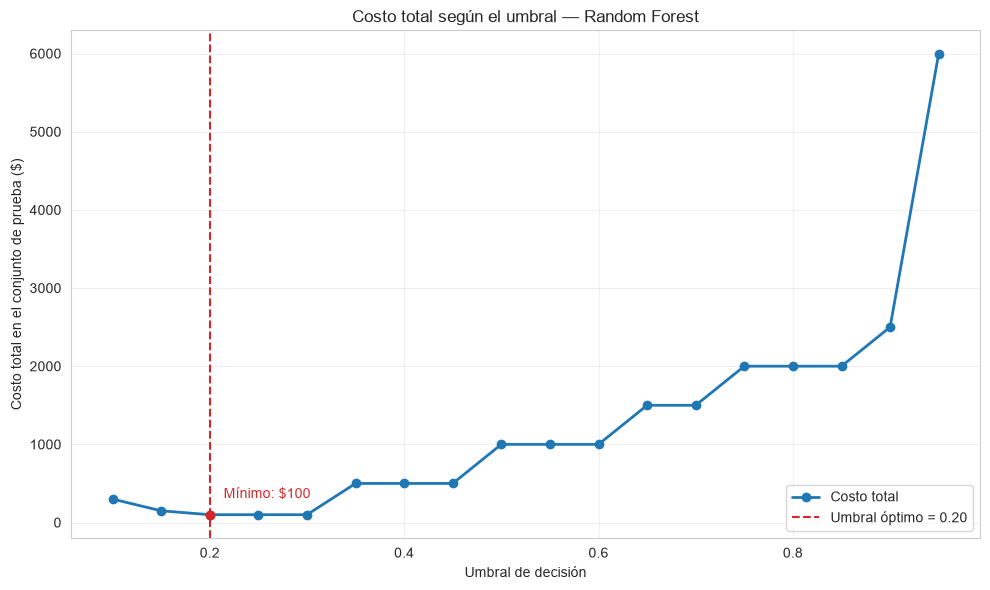

In [7]:
# Elegir el primer umbral de menor costo en caso de empate y graficar la cuadrícula.
indice_optimo = costos_threshold["costo_total"].idxmin()
fila_optima = costos_threshold.loc[indice_optimo]
threshold_optimo = float(fila_optima["umbral"])
costo_minimo = int(fila_optima["costo_total"])

fig, ax = plt.subplots()
ax.plot(
    costos_threshold["umbral"],
    costos_threshold["costo_total"],
    marker="o",
    color="#1f77b4",
    linewidth=2,
    label="Costo total",
)
ax.axvline(
    threshold_optimo,
    color="#d62728",
    linestyle="--",
    label=f"Umbral óptimo = {threshold_optimo:.2f}",
)
ax.scatter([threshold_optimo], [costo_minimo], color="#d62728", zorder=3)
ax.annotate(
    f"Mínimo: ${costo_minimo:,.0f}",
    xy=(threshold_optimo, costo_minimo),
    xytext=(10, 12),
    textcoords="offset points",
    color="#d62728",
)
ax.set_xlabel("Umbral de decisión")
ax.set_ylabel("Costo total en el conjunto de prueba ($)")
ax.set_title("Costo total según el umbral — Random Forest")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "threshold_tuning.png", dpi=150, bbox_inches="tight")
plt.show()

## Identificar el umbral óptimo

¿Qué umbral minimiza el costo en esta búsqueda? ¿Coincide con 0.5? La respuesta depende tanto de las probabilidades producidas por el modelo como de los costos definidos. Revisaremos los dos costos y sus matrices de confusión para entender de dónde surge la diferencia.

In [8]:
# Recuperar costo al umbral óptimo de la cuadrícula y al umbral estándar 0.5.
costo_optimo = int(fila_optima["costo_total"])
fila_050 = costos_threshold.loc[np.isclose(costos_threshold["umbral"], 0.50)].iloc[0]
costo_050 = int(fila_050["costo_total"])
ahorro_threshold = costo_050 - costo_optimo

print(f"Umbral óptimo probado: {threshold_optimo:.2f}")
print(f"Costo mínimo:          ${costo_optimo:,.2f}")
print(f"Costo con umbral 0.50: ${costo_050:,.2f}")
print(f"Ahorro vs. umbral 0.50: ${ahorro_threshold:,.2f}")

# Mostrar matrices comparables: filas reales y columnas predichas en orden [0, 1].
y_pred_optimo = (y_proba_rf >= threshold_optimo).astype(int)
cm_optimo = confusion_matrix(y_test, y_pred_optimo, labels=[0, 1])
print("\nMatriz de confusión con umbral 0.50:")
print(cm_050)
print("\nMatriz de confusión con umbral óptimo:")
print(cm_optimo)

Umbral óptimo probado: 0.20
Costo mínimo:          $100.00
Costo con umbral 0.50: $1,000.00
Ahorro vs. umbral 0.50: $900.00

Matriz de confusión con umbral 0.50:
[[420   0]
 [  2  18]]

Matriz de confusión con umbral óptimo:
[[418   2]
 [  0  20]]


## Interpretación

Si **C_FN > C_FP**, suele convenir explorar umbrales menores que 0.5: aceptar más positivos puede reducir los falsos negativos, aunque probablemente aumenten las falsas alarmas. Si **C_FP > C_FN**, un umbral más alto puede evitar positivos costosos de revisar o atender.

En nuestro ejemplo **C_FN ($500) > C_FP ($50)**, por lo que reducir FN tiene más valor y es razonable que el mínimo de costo se mueva hacia la izquierda. Esto es una tendencia, no una garantía: la forma de las probabilidades, el tamaño de la cuadrícula y los conteos observados determinan el resultado.

## Guía práctica para elegir un umbral

| Relación entre costos | Dirección inicial para explorar | Razonamiento |
|---|---|---|
| C_FN > C_FP | Bajar el umbral | Se busca detectar más positivos y reducir FN, aceptando posiblemente más FP. |
| C_FP > C_FN | Subir el umbral | Se busca limitar alertas falsas y reducir FP, aceptando posiblemente más FN. |
| C_FP = C_FN | Empezar en 0.5 y comparar | El umbral 0.5 es solo un punto de partida; depende de la calibración y de las probabilidades. |

> **Regla de oro:** el umbral 0.5 rara vez es automáticamente óptimo en problemas reales. Estima los costos, define el conjunto de validación, evalúa varios umbrales y revisa las consecuencias operativas de la decisión.

## Conexión con la app Streamlit

En la app de predicción de cultivos agregaremos una pestaña de **factibilidad económica** que permita a la persona usuaria definir C_FP y C_FN y visualizar el umbral óptimo bajo esos supuestos. La interfaz debe explicar claramente qué representa cada costo y advertir que el resultado depende de los datos de evaluación y de la validez de las estimaciones económicas.

## Conclusiones

1. **La matriz de costos** expresa qué impacto económico atribuimos a cada tipo de error.
2. **El costo total** de este ejercicio se calcula como FP × C_FP + FN × C_FN.
3. **Threshold tuning** compara distintas decisiones sobre probabilidades para observar sus errores y costos.
4. **El umbral óptimo depende de los costos, las probabilidades y los datos:** no es necesariamente 0.5 ni tiene que ser igual entre problemas.
5. **La factibilidad económica conecta el modelo con el uso real:** sus supuestos deben explicarse y revisarse con el contexto del negocio.

**Próxima clase:** optimización de hiperparámetros con Optuna y validación cruzada.

In [9]:
# Confirmar dónde quedaron los artefactos generados en esta clase.
print("Clase 9 completada. Revisa reports/figures/threshold_tuning.png y reports/costos_threshold.csv")

Clase 9 completada. Revisa reports/figures/threshold_tuning.png y reports/costos_threshold.csv
